# 6장. Dataset과 DataLoader

In [1]:
# [준비 셀] 모든 노트북의 첫 코드 셀입니다. 항상 먼저 실행하세요.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parents[1]          # docs/manual → 프로젝트 루트
assert (ROOT / "src/bearing_kd").exists(), "docs/manual 폴더에서 노트북을 열어야 합니다"
CODE = ROOT / "docs/manual/code"                 # 챕터별 완성 스크립트 위치
sys.path.insert(0, str(CODE))                    # 스크립트의 함수를 import 해서 쓰기 위해
print("프로젝트 루트 확인 완료:", ROOT.name)

프로젝트 루트 확인 완료: vib-onnx


PyTorch로 학습하려면 데이터를 두 가지 도구에 담아야 합니다.

| 도구 | 역할 | 비유 |
|---|---|---|
| **Dataset** | "i번째 샘플을 줘" 하면 (입력, 정답) 하나를 꺼내 준다 | 문제집 |
| **DataLoader** | Dataset에서 여러 개를 묶어(batch) 순서를 섞어 가며 꺼내 준다 | 문제집에서 16문제씩 뽑아 주는 사람 |

그리고 이 프로젝트만의 단계가 하나 더 있습니다. MOMENT는 512개씩만 받으므로 4,000개 윈도우를 **512 × 8 조각(청크)**으로 나눠야 합니다.

## 6.1 Dataset 만들기

`torch.utils.data.Dataset`을 상속하고 메서드 두 개만 만들면 됩니다.
- `__len__`: 샘플이 모두 몇 개인지
- `__getitem__(i)`: i번째 (입력, 정답)

```python
class WindowDataset(Dataset):
    def __init__(self, window_files):
        # 파일들을 읽어 self.windows [N, 4000], self.labels [N] 에 모아 둔다
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, i):
        x = torch.from_numpy(self.windows[i]).unsqueeze(0)   # [1, 4000] ← 채널 1개
        return x, torch.tensor(self.labels[i])
```

`unsqueeze(0)`로 맨 앞에 크기 1짜리 축을 붙이는 이유: MOMENT 입력은 `[채널 수, 길이]` 모양이고, 우리는 진동 **1채널**이기 때문입니다.

In [2]:
import json
import numpy as np
import torch
import ch06_dataset as ch06

split = json.loads((ROOT / "outputs/manual/split_holdout.json").read_text())
datasets = {name: ch06.WindowDataset([ROOT / f for f in files]) for name, files in split.items()}
for name, ds in datasets.items():
    c = np.bincount(ds.labels, minlength=2)
    print(f"{name:10s} 윈도우 {len(ds):3d}개 (정상 {c[0]}, 고장 {c[1]})")

train      윈도우  84개 (정상 42, 고장 42)
validation 윈도우  28개 (정상 14, 고장 14)
test       윈도우 113개 (정상 57, 고장 56)


In [3]:
train_ds = datasets["train"]
x, y = train_ds[0]
print("x:", tuple(x.shape), x.dtype, "  y:", y.item())
print("이 샘플의 출처:", train_ds.sample_ids[0])

x: (1, 4000) torch.float32   y: 0
이 샘플의 출처: K001/N15_M07_F04_K001_1_windows.npy:0


## 6.2 DataLoader: batch로 묶고 섞기

- `batch_size=16`: 16개씩 묶어 `[16, 1, 4000]` 모양으로 줍니다.
- `shuffle=True`: epoch마다 순서를 섞습니다. 같은 순서로만 배우면 순서까지 외울 수 있기 때문입니다.
- `generator=...manual_seed(42)`: 섞는 순서도 재현할 수 있게 고정합니다.

In [4]:
from torch.utils.data import DataLoader

loader = DataLoader(train_ds, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(42))
batch_x, batch_y = next(iter(loader))
print("batch_x:", tuple(batch_x.shape), " batch_y:", tuple(batch_y.shape))
print("라벨:", batch_y.tolist())
print("한 epoch = batch", len(loader), "번  (", len(train_ds), "÷ 16 올림 )")

batch_x: (16, 1, 4000)  batch_y: (16,)
라벨: [0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1]
한 epoch = batch 6 번  ( 84 ÷ 16 올림 )


In [5]:
def first_labels(seed):
    dl = DataLoader(train_ds, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(seed))
    return next(iter(dl))[1].tolist()

print("seed 42:", first_labels(42))
print("seed 42:", first_labels(42), "← 같은 순서")
print("seed  7:", first_labels(7), "← 다른 순서")

seed 42: [0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1]
seed 42: [0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1] ← 같은 순서
seed  7: [1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0] ← 다른 순서


## 6.3 MOMENT 입력으로 바꾸기: 512 × 8 청크

4,000은 512로 나누어떨어지지 않습니다(512 × 7 = 3,584, 512 × 8 = 4,096). 그래서:

1. 뒤에 **0을 96개** 붙여 4,096개로 만든다 (패딩)
2. 512개씩 **8조각**으로 자른다
3. 붙인 96칸은 가짜이므로 **mask = 0**으로 표시한다 (진짜 샘플은 1)

```text
윈도우 [4000]  →  [0‥512) [512‥1024) … [3584‥4096)
                  청크1    청크2         청크8 (앞 416개 진짜 + 96개 0)
mask             1111…    1111…         1111…(416개) 0000…(96개)
```

모델은 청크마다 따로 점수를 내고, 나중에 **8개 점수를 평균**해서 윈도우 하나의 판정으로 씁니다(12장).

In [6]:
chunks, mask, chunk_y = ch06.make_moment_chunks(batch_x, batch_y)
print("batch_x", tuple(batch_x.shape), "→ chunks", tuple(chunks.shape), "(16 × 8 = 128)")
print("mask", tuple(mask.shape), " 청크 라벨", tuple(chunk_y.shape))
print("\n윈도우 1개(청크 8개)의 mask 합:", mask[:8].sum().item(), "← 진짜 샘플 4000개")
print("8번째 청크의 mask: 앞 416개", mask[7, :416].sum().item(), ", 뒤 96개", mask[7, 416:].sum().item())
print("청크 라벨 앞 16개:", chunk_y[:16].tolist(), "← 윈도우 라벨을 8번씩 복사")

batch_x (16, 1, 4000) → chunks (128, 1, 512) (16 × 8 = 128)
mask (128, 512)  청크 라벨 (128,)

윈도우 1개(청크 8개)의 mask 합: 4000.0 ← 진짜 샘플 4000개
8번째 청크의 mask: 앞 416개 416.0 , 뒤 96개 0.0
청크 라벨 앞 16개: [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1] ← 윈도우 라벨을 8번씩 복사


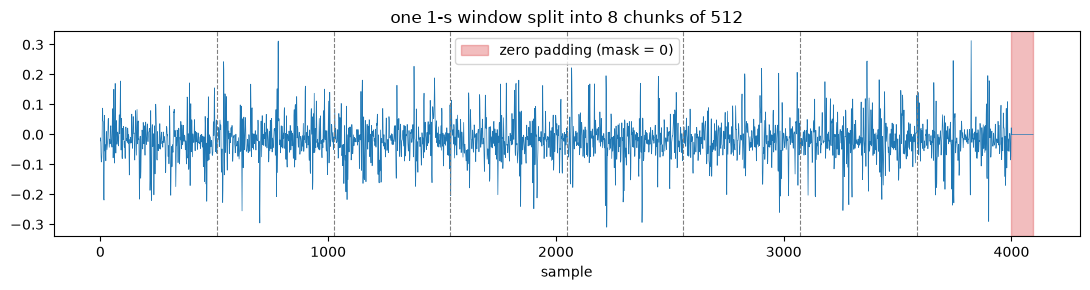

In [7]:
import matplotlib.pyplot as plt

win = batch_x[0, 0].numpy()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(np.arange(4096), np.pad(win, (0, 96)), lw=0.5)
for k in range(1, 8):
    ax.axvline(512 * k, color="gray", ls="--", lw=0.8)
ax.axvspan(4000, 4096, color="C3", alpha=0.3, label="zero padding (mask = 0)")
ax.set_title("one 1-s window split into 8 chunks of 512"); ax.set_xlabel("sample"); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
restored = chunks[:8, 0].reshape(-1)[:4000]
print("청크 8개를 이어 붙이면 원래 윈도우와 같은가?", torch.equal(restored, batch_x[0, 0]))

# 실제 프로젝트 코드와 비교
sys.path.insert(0, str(ROOT / "src"))
from bearing_kd.data import make_moment_chunks as project_chunks
p_chunks, p_mask, p_y = project_chunks(batch_x, batch_y)
print("프로젝트 코드와 같은가?", torch.equal(chunks, p_chunks) and torch.equal(mask, p_mask) and torch.equal(chunk_y, p_y))

청크 8개를 이어 붙이면 원래 윈도우와 같은가? True


프로젝트 코드와 같은가? True


## 6.4 데이터 지문(fingerprint)

Dataset은 읽은 파일의 이름과 내용으로 **지문(SHA-256 해시)**을 만듭니다. 파일이 한 바이트라도 바뀌거나 순서가 바뀌면 지문도 바뀝니다.

왜 필요할까요? 11장에서 Teacher의 예측을 파일로 저장해 두고(캐시) Student 학습에 씁니다. 만약 캐시를 만든 뒤 데이터가 바뀌면, **Teacher 예측과 윈도우의 짝이 어긋난 채로** 조용히 학습이 진행됩니다. 지문을 캐시에 같이 저장해 두고 학습 전에 비교하면 이런 사고를 막을 수 있습니다.

In [9]:
files = [ROOT / f for f in split["train"]]
fp1 = ch06.WindowDataset(files).fingerprint
fp2 = ch06.WindowDataset(files).fingerprint
fp3 = ch06.WindowDataset(list(reversed(files))).fingerprint
print("같은 파일, 같은 순서:", fp1 == fp2)
print("같은 파일, 순서만 반대:", fp1 == fp3, "← 지문이 달라져서 어긋남을 잡아낸다")

같은 파일, 같은 순서: True
같은 파일, 순서만 반대: False ← 지문이 달라져서 어긋남을 잡아낸다


## 6.5 정리

```text
split JSON ─▶ Dataset (윈도우 [N,4000], 라벨 [N], 지문)
          ─▶ DataLoader (batch [16,1,4000], 섞기, seed)
          ─▶ make_moment_chunks (청크 [128,1,512] + mask [128,512])
          ─▶ MOMENT 모델 (7장)
```

## 6장 완성 코드: `code/ch06_dataset.py`

In [10]:
%run code/ch06_dataset.py

train      윈도우   84개 (정상 42, 고장 42)  지문 20de101d5879…
validation 윈도우   28개 (정상 14, 고장 14)  지문 f5768e3160b1…
test       윈도우  113개 (정상 57, 고장 56)  지문 193c0d7efe23…

샘플 1개: x (1, 4000) torch.float32, y = 0  ← K001/N15_M07_F04_K001_1_windows.npy:0
batch 1개: x (16, 1, 4000), y (16,) → 라벨 [0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1]
한 epoch = batch 6번

MOMENT 입력: chunks (128, 1, 512), mask (128, 512), 청크 라벨 (128,)
윈도우 1개의 mask 합계 = 4000 (실제 샘플 4000개, 패딩 96개는 0)
청크 8개를 이어 붙이면 원래 윈도우와 같은가? True


In [11]:
from IPython.display import Code
Code(filename=str(CODE / "ch06_dataset.py"), language="python")

"""6장 완성 코드: split JSON → PyTorch Dataset → DataLoader → MOMENT 입력(512 × 8 청크 + mask).

src/bearing_kd/data.py의 BearingWindowDataset, make_moment_chunks를 읽기 쉽게 줄인 버전이다.

실행 (프로젝트 루트에서, 4·5장 결과 사용):
    python docs/manual/code/ch06_dataset.py
"""

import argparse
import hashlib
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

ROOT = Path(__file__).resolve().parents[3]
WINDOW_SIZE = 4_000
CHUNK_SIZE = 512       # MOMENT가 한 번에 받는 길이 (고정)


class WindowDataset(Dataset):
    """윈도우 파일 목록을 읽어 (신호, 라벨) 쌍을 하나씩 꺼내 주는 상자."""

    def __init__(self, window_files):
        windows, labels, sample_ids = [], [], []
        digest = hashlib.sha256()
        for path in window_files:
            path = Path(path)
            w = np.load(path)                                          # [파일당 윈도우 수, 4000]
            y = np.load(path.with_name(path.name.replace("_windows", "_labels")))
            assert w.shape[1] == WINDOW_SIZE and len(w) == len(y)
            windows.append(w.astype(np.float32))
            labels.append(y.astype(np.int64))
            sample_ids += [f"{path.parent.name}/{path.name}:{i}" for i in range(len(w))]
            digest.update(path.name.encode())
            digest.update(hashlib.sha256(path.read_bytes()).hexdigest().encode())
        self.windows = np.concatenate(windows)   # [전체 윈도우 수, 4000]
        self.labels = np.concatenate(labels)     # [전체 윈도우 수]
        self.sample_ids = sample_ids             # 각 윈도우가 어느 파일 몇 번째인지
        self.fingerprint = digest.hexdigest()    # 데이터 내용이 바뀌면 이 값도 바뀐다

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, index):
        x = torch.from_numpy(self.windows[index]).unsqueeze(0)  # [1, 4000]: 채널 1개
        y = torch.tensor(self.labels[index])
        return x, y


def make_moment_chunks(batch_x, batch_y=None, chunk=CHUNK_SIZE):
    """[B, 1, 4000] → [B*8, 1, 512] 청크 + [B*8, 512] mask.

    4000은 512로 나누어떨어지지 않으므로 4096(=512×8)까지 0을 채우고,
    채운 96칸은 mask=0으로 표시해 모델이 무시하게 한다.
    """
    b, c, length = batch_x.shape
    count = -(-length // chunk)                                  # 올림 나눗셈: 8
    padded = F.pad(batch_x, (0, count * chunk - length))          # [B, 1, 4096]
    chunks = padded.reshape(b, c, count, chunk).permute(0, 2, 1, 3).reshape(b * count, c, chunk)
    # mask는 입력과 같은 장치(CPU/GPU)에 만들어야 한다. 다르면 "Expected all tensors to be on the same device" 에러
    mask = (torch.arange(count * chunk, device=batch_x.device) < length).to(batch_x.dtype).reshape(count, chunk).repeat(b, 1)
    labels = None if batch_y is None else batch_y.repeat_interleave(count)
    return chunks, mask, labels


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--split", default="outputs/manual/split_holdout.json")
    parser.add_argument("--batch-size", type=int, default=16)
    args = parser.parse_args()

    split = json.loads((ROOT / args.split).read_text())
    datasets = {name: WindowDataset([ROOT / f for f in files]) for name, files in split.items() if files}
    for name, ds in datasets.items():
        counts = np.bincount(ds.labels, minlength=2)
        print(f"{name:10s} 윈도우 {len(ds):4d}개 (정상 {counts[0]}, 고장 {counts[1]})  지문 {ds.fingerprint[:12]}…")

    x, y = datasets["train"][0]
    print(f"\n샘플 1개: x {tuple(x.shape)} {x.dtype}, y = {y.item()}  ← {datasets['train'].sample_ids[0]}")

    loader = DataLoader(datasets["train"], batch_size=args.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    batch_x, batch_y = next(iter(loader))
    print(f"batch 1개: x {tuple(batch_x.shape)}, y {tuple(batch_y.shape)} → 라벨 {batch_y.tolist()}")
    print(f"한 epoch = batch {len(loader)}번")

    chunks, mask, chunk_y = make_moment_chunks(batch_x, batch_y)
    print(f"\nMOMENT 입력: chunks {tuple(chunks.shape)}, mask {tuple(mask.shape)}, 청크 라벨 {tuple(chunk_y.shape)}")
    print(f"윈도우 1개의 mask 합계 = {mask[:8].su